In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from matplotlib.ticker import MaxNLocator

# https://matplotlib.org/stable/users/explain/colors/colormaps.html#qualitative


In [61]:
# read and process dataset

path = r"data\src\conflated_database___2026_03_31__11_14_35.xlsx"

df = pd.read_excel(path, sheet_name="TextReading_Included")
df = df[df.topic.notna()].reset_index(drop=True)
df.topic = df.topic.apply(lambda x: x.split(", "))
df.Year = df.Year.astype(int)

df_model = df[df.topic.apply(lambda x: "Model" in x)].reset_index(drop=True)

print(f"papers -- total: {df.shape[0]}")
print(f"papers -- new generative method : {df_model.shape[0]}")

papers -- total: 72
papers -- new generative method : 65


# *SUBSET DATASET COLUMNS*

# MODEL

In [62]:
# preprocessing
def process_model_df(df_model):

    df_model["Discriminative/Generative"] = df_model["Core Generative Paradigm"].apply(lambda x: "Discriminative" if "Discriminative" in x else "Generative")

    df_model["Model"] = \
    df_model["Core Generative Paradigm"].apply(lambda x: 
        "Hybrid: Discriminative" if ("Hybrid" in x and "Discriminative" in x) else 
        (
            "Hybrid: Generative" if "Hybrid" in x else x
        )
    )

    return df_model


# plots
MODEL_COLOR_MAP = {
    'Autoregressive': 'tab:blue',
    'Diffusion': 'tab:orange',
    'Discriminative': 'tab:green',
    'GAN': 'tab:red',
    'Hybrid: Discriminative': 'tab:purple',
    'Hybrid: Generative': 'tab:brown',
    'VAE': 'tab:pink',
}


def plot_discriminative_vs_generative(df_model):
    group_counts = df_model.groupby(['Year', 'Discriminative/Generative']).size().unstack(fill_value=0)
    group_counts = group_counts.sort_index()

    cmap = plt.cm.tab20b
    # cmap = plt.cm.terrain
    num_colors = len(group_counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    ax = group_counts.plot(
        kind='bar',
        stacked=True,
        rot=0,
        ylabel="# papers",
        color=colors,
    )


def plot_model_per_year(df_model):
    model_counts = df_model.groupby(['Year', 'Model']).size().unstack(fill_value=0).sort_index()
    colors = [
        MODEL_COLOR_MAP.get(col, "#cccccc")
        for col in model_counts.columns
    ]

    ax = model_counts.plot(
        kind='bar',
        stacked=True,
        rot=0,
        ylabel="# papers",
        color=colors,
    )


def plot_model(df_model):    
    model_counts = df_model["Model"].value_counts(ascending=True)
    colors = [MODEL_COLOR_MAP[m] for m in model_counts.index]
    # colors = 

    ax = model_counts.plot(kind="barh", color=colors)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel("# papers")
    ax.set_ylabel("ML model")

In [63]:
df_model = process_model_df(df_model)

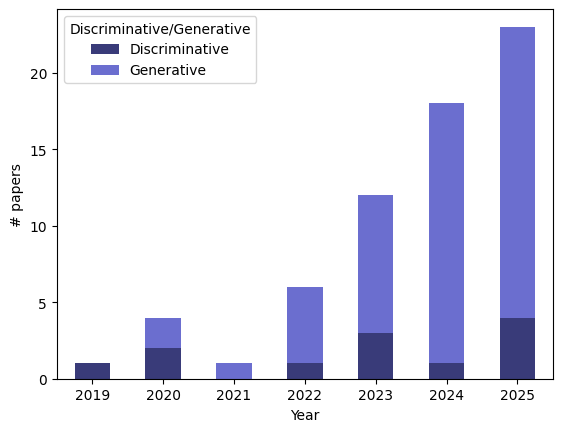

In [39]:
plot_discriminative_vs_generative(df_model)

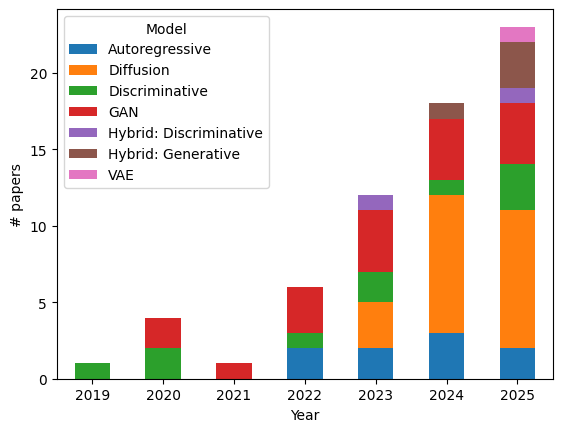

In [40]:
plot_model_per_year(df_model)

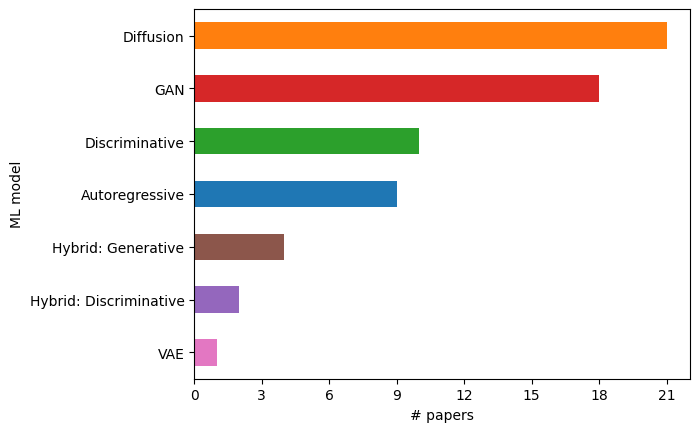

In [41]:
plot_model(df_model)

# PRE PROCESSING

In [46]:
def split_levels(x):
    if ':' in x:
        l1, l2 = x.split(':', 1)
        return pd.Series([l1.strip(), l2.strip()])
    else:
        return pd.Series([x.strip(), None])


def two_level_barh(df, col, xlabel=None, ylabel=None):

    df[f"M_{col}"] = df[col].apply(lambda x: x.split(", "))

    exploded = df[f"M_{col}"].explode()
    exploded = exploded.apply(split_levels)
    exploded.columns = ['Level1', 'Level2']
    exploded['Level2'] = exploded['Level2'].fillna('Absent')

    counts = exploded.groupby(['Level1', 'Level2']).size().unstack(fill_value=0)
    totals = counts.sum(axis=1)
    counts = counts.loc[totals.sort_values(ascending=True).index]

    counts.plot(
        kind='barh',
        stacked=True,
    )
    if xlabel is not None:
        plt.xlabel(xlabel)
    if ylabel is not None:
        plt.ylabel(ylabel)

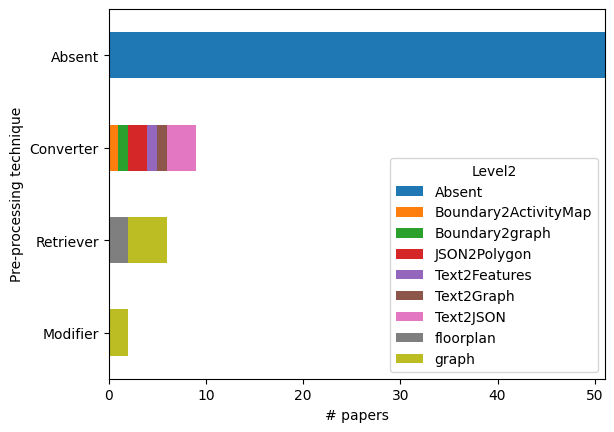

In [11]:
two_level_barh(df_model, "Pre processing outside generative model", xlabel="# papers", ylabel="Pre-processing technique")

# POST PROCESSING

In [13]:
def plot_postprocessing(df_model):
    df_model["postprocessing"] = df_model["Post processing outside generative model"].apply(lambda x: x.split(", "))
    pp_counts = df_model["postprocessing"].explode().value_counts(ascending=True)
    
    cmap = plt.cm.tab20
    num_colors = len(pp_counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    pp_counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="Post-processing technique",
        color=colors,
    )

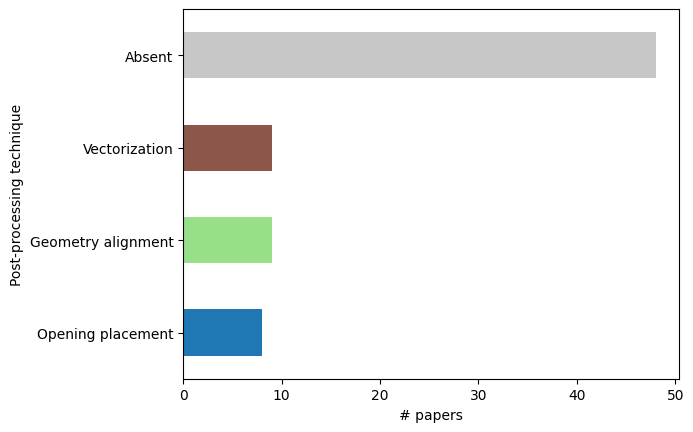

In [14]:
plot_postprocessing(df_model)

# INPUT

In [24]:
def preprocess_input(df_model):
    df_model["input"] = df_model["Neural Input (modality: semantics)"].apply(lambda x: set(x.split(", ")))
    df_model["input_modality"] = df_model["input"].apply(lambda x: set(i.split(": ")[0] for i in x))
    df_model["input_content"] = df_model["input"].apply(lambda x: set(i.split(": ")[1] for i in x if i != "Absent")) ### to check later !!!
    return df_model


def plot_input_modality(df_model):

    counts = df_model["input_modality"].explode().value_counts(ascending=True)

    cmap = plt.cm.tab20
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="Input modality",
        color=colors,
    )


def plot_input_content(df_model):

    counts = df_model["input_content"].explode().value_counts(ascending=True)

    cmap = plt.cm.tab20
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="Input content",
        color=colors,
    )


def get_csv_modality_content(df_model):
    levels = df_model["input"].explode().str.split(':', n=1, expand=True)
    levels.columns = ['level1', 'level2']

    # Clean whitespace
    levels = levels.apply(lambda col: col.str.strip())

    # Count co-occurrences
    counts = (
        levels
        .groupby(['level1', 'level2'])
        .size()
        .reset_index(name='count')
    )

    # Export
    counts.to_csv("data/results/input_modality_content.csv", index=False)


def plot_sankey_input(df_model):

    get_csv_modality_content(df_model)

    df_coocurence = pd.read_csv("data/results/input_modality_content.csv")

    # Keep only needed columns
    df_coocurence = df_coocurence[["level1", "level2", "count"]]

    # Optional: remove tiny flows if diagram is too crowded
    # df = df[df["Count"] >= 2]

    sources = df_coocurence["level1"].astype(str)
    targets = df_coocurence["level2"].astype(str)
    values = df_coocurence["count"]

    # Create unique node list
    nodes = pd.Index(pd.concat([sources, targets]).unique())

    # Map labels to numeric IDs
    source_ids = sources.map(nodes.get_loc)
    target_ids = targets.map(nodes.get_loc)

    fig = go.Figure(data=[go.Sankey(
        node=dict(
            label=nodes.tolist(),
            pad=15,
            thickness=18
        ),
        link=dict(
            source=source_ids,
            target=target_ids,
            value=values
        )
    )])

    fig.update_layout(
        title_text="Modality → Content",
        font_size=10,
        width=1200,
        height=800
    )

    fig.write_image(
        "data/results/input_modality_content.svg",
        scale=4,
    )


In [16]:
df_model = preprocess_input(df_model)

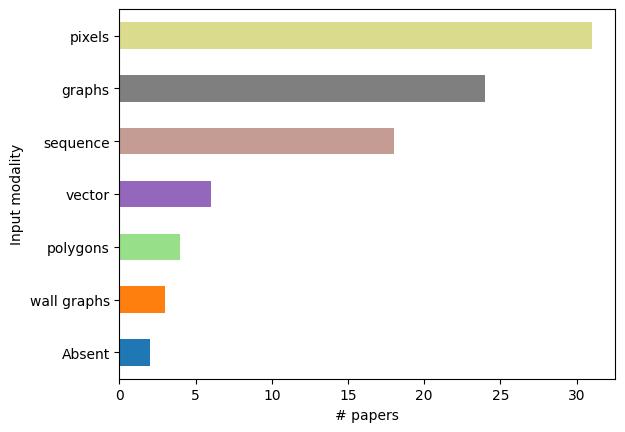

In [17]:
plot_input_modality(df_model)

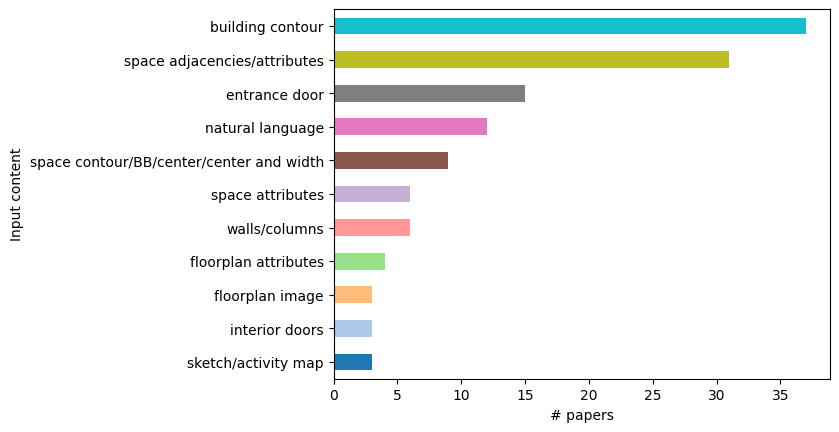

In [18]:
plot_input_content(df_model)

In [25]:
plot_sankey_input(df_model)

# OUTPUT

In [32]:
def plot_output_modality(df_model):
    df_model["output_modality"] = df_model["Neural Output (modality)"].apply(lambda x: x.split(", "))
    counts = df_model["output_modality"].explode().value_counts(ascending=True)

    cmap = plt.cm.Set3
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="Output modality",
        color=colors,
    )



def plot_output_content(df_model):
    df_model["output_content"] = df_model["Ultimate Output semantics"].apply(lambda x: set(x.split(", ")))
    counts = df_model["output_content"].explode().value_counts(ascending=True)

    cmap = plt.cm.Set3
    num_colors = len(counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="Output content",
        color=colors,
    )


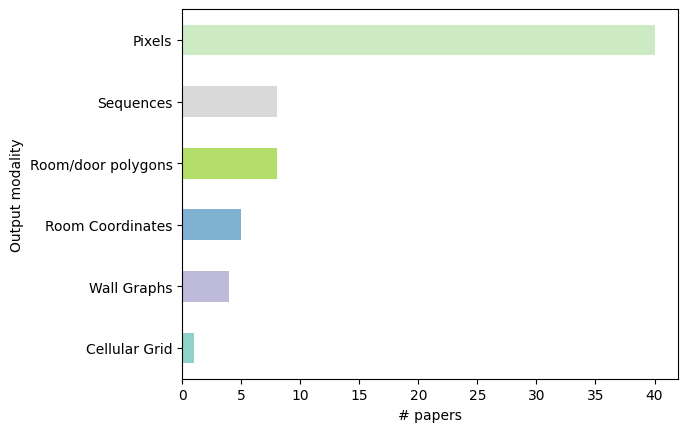

In [31]:
plot_output_modality(df_model)

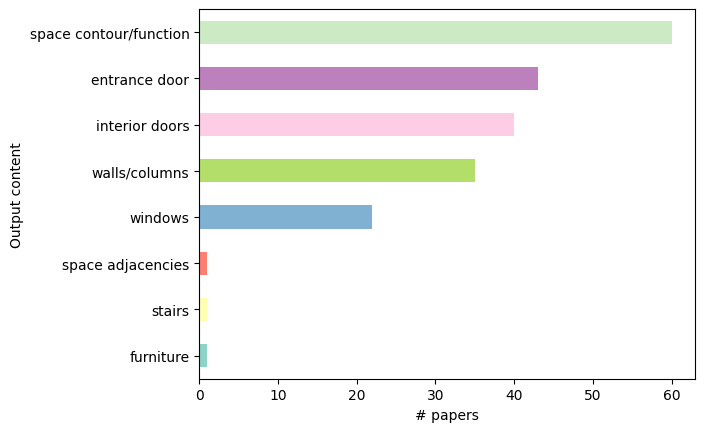

In [33]:
plot_output_content(df_model)

# INPUT-OUTPUT

In [ ]:
///

# *FULL DATASET COLUMNS*

# DATASET

In [64]:
def merge_datasets(x):
    groups = ["LIFULL", "RPLAN", "GeLayout", "MSD", "Tell2Design"]
    return x if x in groups else "other dataset"


def plot_dataset_per_year(df):

    df["dataset"] = df["Dataset"].apply(lambda x: x.split(", "))

    dataset_exploded = df.explode("dataset")
    dataset_exploded["dataset_grouped"] = dataset_exploded["dataset"].apply(merge_datasets)

    dataset_counts = (
        dataset_exploded
        .groupby(['Year', 'dataset_grouped'])
        .size()
        .unstack(fill_value=0)
    )

    cmap = plt.cm.Set3
    num_colors = len(dataset_counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    ax = dataset_counts.plot(
        kind='bar',
        stacked=True,
        ylabel='# papers',
        color=colors,
        # figsize=(12,6)
    )
    ax.tick_params(axis='x', rotation=0)

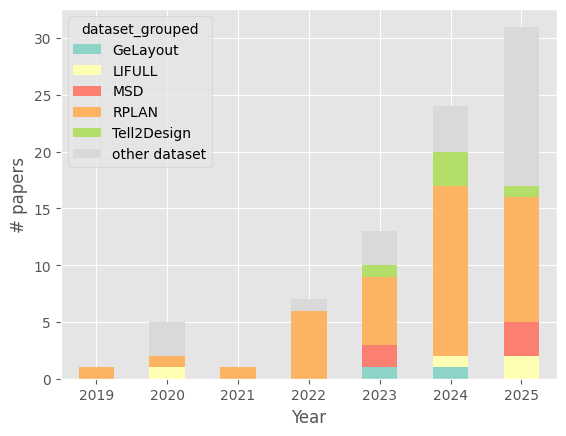

In [67]:
plot_dataset_per_year(df)

# GENERALIZABILITY

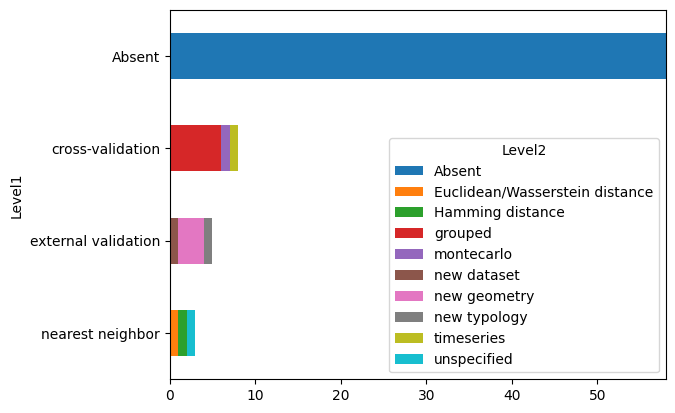

In [109]:
two_level_barh(df, "Generalizability")

# USER STUDIES

In [66]:
def plot_user_studies(df):

    df["user_studies"] = df["User Studies"].apply(lambda x: x.split(", "))
    pp_counts = df["user_studies"].explode().value_counts(ascending=True)
    
    cmap = plt.cm.Set3
    # cmap = plt.cm.Pastel1
    # cmap = plt.cm.tab20b
    num_colors = len(pp_counts.index)
    colors = [
        cmap(i / num_colors) for i in range(num_colors)
    ]

    pp_counts.plot(
        kind="barh", 
        xlabel="# papers", 
        ylabel="User study type",
        color=colors,
    )

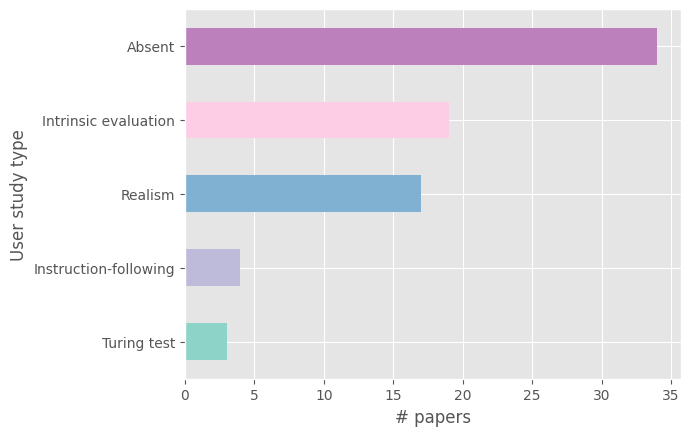

In [63]:
plot_user_studies(df)

# METRICS

In [43]:
df["AF: Intrinsic"]

0     Quality: RAI, Quality: Space Property Proportion
1                                               Absent
2                                               Absent
3                                               Absent
4                                               Absent
                            ...                       
67                                              Absent
68                                              Absent
69                                              Absent
70                 Validity: Percent of isolated rooms
71                                       Diversity: IS
Name: AF: Intrinsic, Length: 72, dtype: str

In [ ]:
df["AF: Intrinsic"]

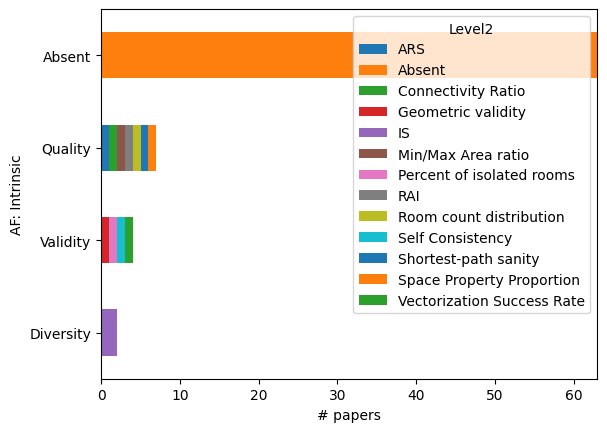

In [47]:
two_level_barh(df, "AF: Intrinsic", xlabel="# papers", ylabel="AF: Intrinsic")

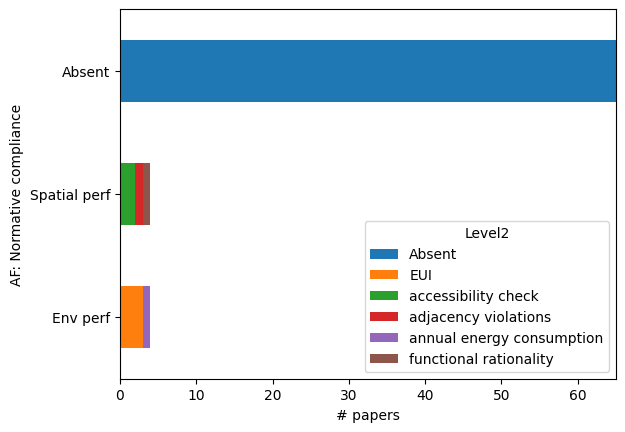

In [48]:
two_level_barh(df, "AF: Normative compliance", xlabel="# papers", ylabel="AF: Normative compliance")

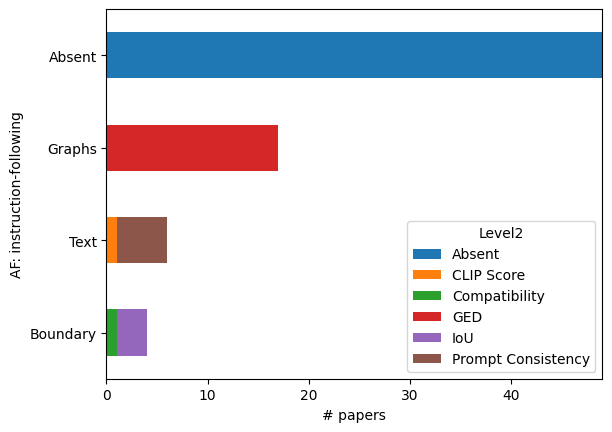

In [49]:
two_level_barh(df, "AF: instruction-following", xlabel="# papers", ylabel="AF: instruction-following")

In [51]:
# two_level_barh(df, "AF: similarity", xlabel="# papers", ylabel="AF: similarity")

In [54]:
df["AF: similarity"]

0                                                Absent
1     IoU, mIoU, Pixel-level classification performance
2                                  IoU, Embeddings: FID
3                                           IoU (CVAAD)
4                                       Embeddings: FID
                            ...                        
67                Mean IoU, Graphs: Graph Compatibility
68                                               Absent
69                                               Absent
70         Attributes: VGA, Attributes: room statistics
71                     Embeddings: FID, Embeddings: KID
Name: AF: similarity, Length: 72, dtype: str

<Axes: ylabel='similarity'>

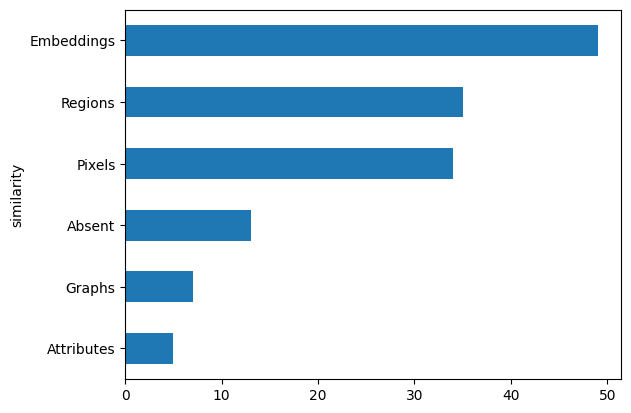

In [64]:
def process_similarity(metric):
    if "Absent" in metric:
        return "Absent"
    elif "Embeddings" in metric:
        return "Embeddings" 
    elif "Graphs" in metric:
        return "Graphs"
    elif "Attributes" in metric:
        return "Attributes"
    elif ("IoU" in metric) or ("Chamfer" in metric):
        return "Regions"
    else:
        return "Pixels"
    

df["similarity"] = df["AF: similarity"].apply(lambda x: x.split(", "))
exploded_similarity = df["similarity"].explode().apply(process_similarity)
exploded_similarity.value_counts(ascending=True).plot(kind="barh")

<Axes: ylabel='instruction_f'>

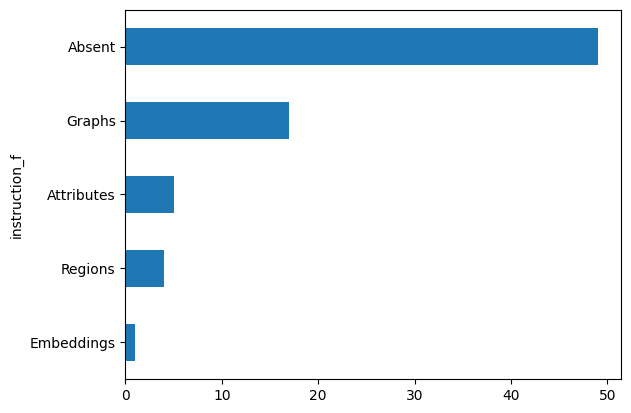

In [65]:
def process_instruction_following(metric):
    if "Absent" in metric:
        return "Absent"
    elif "Embeddings" in metric:
        return "Embeddings" 
    elif "Graphs" in metric:
        return "Graphs"
    elif "Attributes" in metric:
        return "Attributes"
    elif "Boundary":
        return "Regions"
    else:
        raise ValueError
    

df["instruction_f"] = df["AF: instruction-following"].apply(lambda x: x.split(", "))
exploded_instruction_f = df["instruction_f"].explode().apply(process_instruction_following)
exploded_instruction_f.value_counts(ascending=True).plot(kind="barh")

<Axes: ylabel='normative_c'>

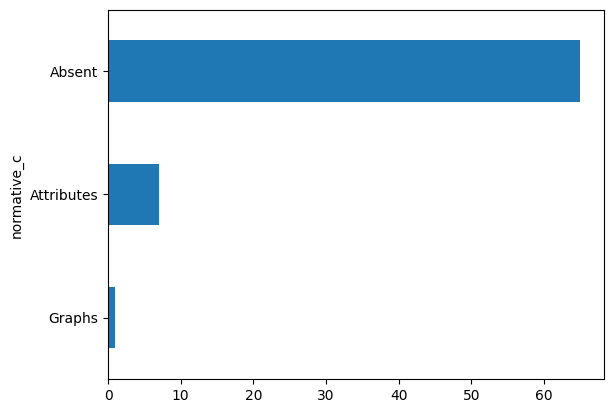

In [66]:
def process_normative_compliance(metric):
    if "Absent" in metric:
        return "Absent"
    elif "Graphs" in metric:
        return "Graphs"
    elif "Attributes" in metric:
        return "Attributes"
    else:
        raise ValueError
    

df["normative_c"] = df["AF: Normative compliance"].apply(lambda x: x.split(", "))
exploded_normative_c = df["normative_c"].explode().apply(process_normative_compliance)
exploded_normative_c.value_counts(ascending=True).plot(kind="barh")

<Axes: ylabel='intrinsic'>

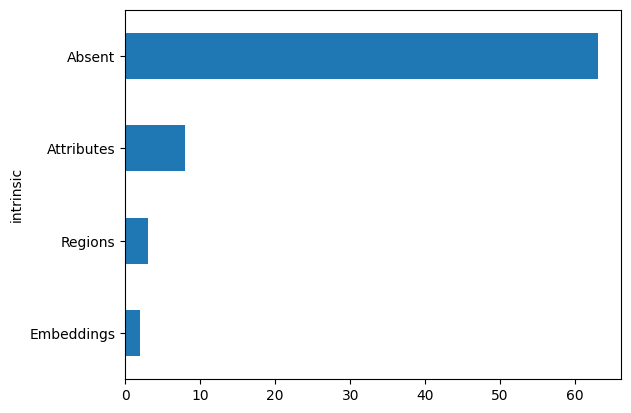

In [68]:
def process_intrinsic(metric):
    if "Absent" in metric:
        return "Absent"
    elif "Embeddings" in metric:
        return "Embeddings" 
    elif "Regions" in metric:
        return "Regions"
    elif "Attributes" in metric:
        return "Attributes"
    else:
        raise ValueError
    

df["intrinsic"] = df["AF: Intrinsic"].apply(lambda x: x.split(", "))
exploded_intrinsic = df["intrinsic"].explode().apply(process_intrinsic)
exploded_intrinsic.value_counts(ascending=True).plot(kind="barh")